# RoadLogic, journal version: what changed

Branch `feature/keep`. Everything in this notebook is produced by running the pipeline here: the
specifications are planned by clingo, executed by Frenetix and checked by the monitor. A full run
takes about 15 minutes. Finished experiments are cached in `demo_output/`, so a second run is quick.

**Status in one paragraph.** The `keep` constraint works end to end: it is parsed, encoded in the
ASP planning problem, and checked on the simulated trace. Speed is a new modifier, durations are
honoured, and contradicting specifications are reported as having no plan. The monitor now checks
keeps and the scenario duration. The Frenetix speed patch helped a single car hold a speed but caused a
collision with two cars. Section 8 has the cause, and a fix that handles both, not yet the default. The monitor now has
clocks, so a duration on any segment is checked (section 11).

| where | what |
|---|---|
| this notebook | the experiments, with specs, commands, new code and outputs |
| `demo_output/<experiment>/` | every intermediate file of each run: ASP program, plan, scenario, trace, animations, verdict |
| `docs/new_features.md` | the plain list of new features, for the email |
| `docs/review-queue.md`, section 0 | the code worth reviewing, in order |
| `.claude/PLAN.md`, end | decisions and where to continue |

Sections 1 to 6 are the features, 7 to 11 are experiments about simulation.

In [1]:
import os, sys, warnings
from collections import defaultdict
while not os.path.exists("planning") and os.getcwd() != "/":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("tests"))
warnings.simplefilter("ignore")

import pandas as pd
import matplotlib.pyplot as plt
from demo_pipeline import (OUT, PAPER, RECOMMENDED, PATCHED, draw_automaton, monitor_verdict,
                           run_experiment, show_code, show_images, show_lines,
                           simulation_folder, simulation_length)
from plan_checks import CONTROLLER_LP, HERE, Planner, goal_witnesses, lanes_of, speeds_of
from planning.asp.generate_plans import NoModelException

def spec(name):
    return os.path.join(HERE, name)

def plan_for(name, n=1, imax=12):
    import tempfile
    out = tempfile.mkdtemp(prefix="nb_plan_")
    planner = Planner(spec(name), out_path=out)
    return planner.plans(n=n, external_rules=[CONTROLLER_LP], visualize=False, imax=imax), out, planner

print("outputs go to", OUT)

outputs go to /home/figlerg/dev/artifact_iccps26/roadlogic/demo_output


## 1. Keep a lane for the whole scenario

**What is new.** `keep(<expression>)` from the standard. Written as a scenario member it must hold
at every step of the scenario. The planner encodes it as an integrity constraint, so a plan that
breaks it is never produced. The monitor checks the same thing on the simulated trace.

**Spec.** `tests/keep_scenario_scope.osc`, the usual overtake, but car1 must stay in lane 2 throughout.

**Command.** Planning only: `python tests/run_keep_tests.py keep_scenario_scope.osc -v`.
The full pipeline is in `demo_output/e1_keep_one_lane/commands.sh`.

In [2]:
print(open(spec("keep_scenario_scope.osc")).read())

# Scenario-scoped keep: the invariant is declared as a scenario member, so per 7.3.11.2 it
# holds for the whole lifetime of the scenario, across every phase of every actor.
# Contrast with keep.osc, where the same constraint sits inside a single behavior invocation.
# car1 is pinned to lane 2 because lanes are 1..3 and ego needs a lane strictly left of car1.
#
# The final gap is 13m..25m rather than the 5m..10m used in exp_002_b, and that difference is
# forced by the model rather than by taste. Merging back into car1's lane triggers the "right
# change version" rule in dynamics.lp, which forbids the move unless car1 is more than
# safety_distance_back = 7 behind ego's previous segment. A lane change also needs
# Vel_lon >= min_change_speed = 6 per controller.lp. Together the gap right after merging is at
# least 6 + 7 = 13, so a 5m..10m goal is unsatisfiable.
#
# exp_002_b gets away with 5m..10m only because car1 is free to change lane there and does:
# its baseline trace is [2,2,2,2

In [3]:
# the new code: a keep is written as its own negation, and that becomes an integrity constraint
from planning.intermediate_structure.Constraint import Invariant
show_code(Invariant.asp_violation_bodies, 22)

planning/intermediate_structure/Constraint.py:889

  889      def asp_violation_bodies(self):
  890          """Rule bodies for `#program check(t)` that hold exactly when the invariant is broken at t.
  891  
  892          A keep for the whole scenario turns each into an integrity constraint. A keep inside a
  893          behavior invocation turns each into keep_broken(i,t), see Planner._invocation_keep_rules.
  894          """
  895          c = self.constraint
  896  
  897          if isinstance(c, AbsoluteConstraint):
  898              value = c.value
  899              if isinstance(value, float) and value.is_integer():
  900                  value = int(value)
  901  
  902              op = self.FORBIDDEN.get(c.relation)
  903              if op is None:
  904                  raise NotImplementedError(f"Cannot negate relation {c.relation} for an invariant.")
  905  
  906              var = 'X'
  907              return [f"{self._holds(c.actor, c.modifier, var)}, {var} {op}

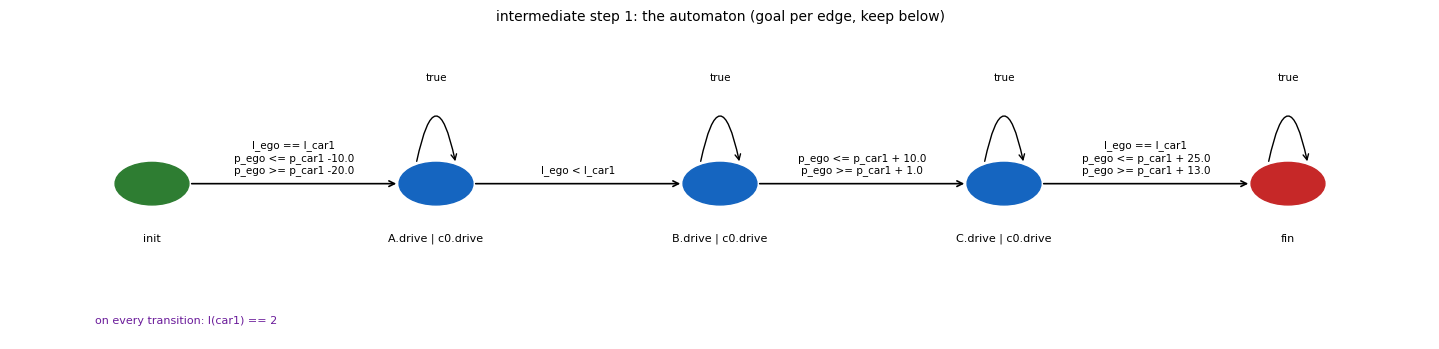

intermediate step 2: what the keep becomes in the ASP program (instance.lp)

goal(T1,T2,T3,t) :-  goal1(T1),goal2(T2),goal3(T3), 0 <= T1<=T2<=T3 <= t, 3 <= T3 <= 20.
:- query(t), not goal(_,_,_,t).
:- query(t), goal(_,_,_,t-1).
:- holds(state(car1, loc(_,X), dyn(_,_)), t), X != 2.

intermediate step 3: the plan (plan.txt)

last step: 9
goal times, one tuple per valid split: [(3, 4, 9), (3, 5, 9), (4, 4, 9), (4, 5, 9), (5, 5, 9)]

car1
  t [s]          0    1    2    3    4    5    6    7    8    9
  position      10   11   14   17   25   26   27   34   36   37
  lane           2    2    2    2    2    2    2    2    2    2
  speed [mps]    1    3    3    8    1    1    7    2    1    3

ego
  t [s]          0    1    2    3    4    5    6    7    8    9
  position       0    1    8   14   26   36   44   45   54   61
  lane           2    2    2    1    1    1    1    1    1    2
  speed [mps]    1    7    6   12   10    8    1    9    7    1



In [4]:
e1 = run_experiment("e1_keep_one_lane", spec("keep_scenario_scope.osc"), RECOMMENDED)
fig = draw_automaton(spec("keep_scenario_scope.osc"), "intermediate step 1: the automaton (goal per edge, keep below)")
plt.show()
print("intermediate step 2: what the keep becomes in the ASP program (instance.lp)\n")
show_lines(f"{e1}/instance.lp", [":- holds", "goal("])
print("\nintermediate step 3: the plan (plan.txt)\n")
print(open(f"{e1}/plan.txt").read())

"intermediate step 4: the plan, as the solver sees it",output: the simulation

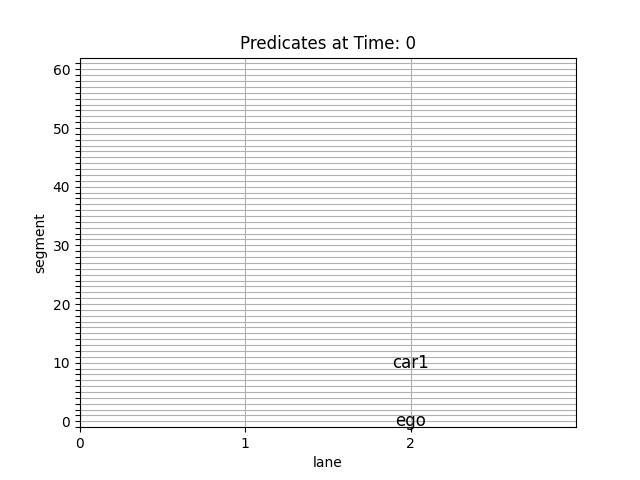
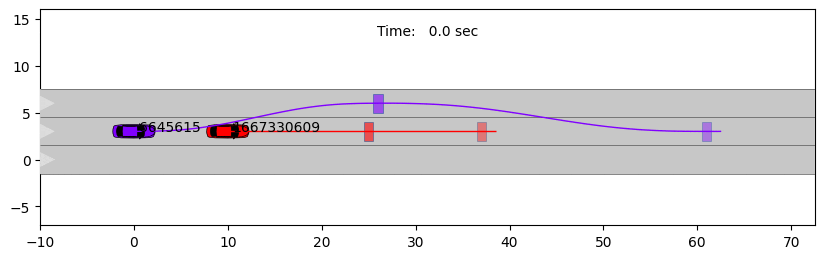

monitor verdict on the simulated trace: POSITIVE
Watch car1: it never leaves its lane while the other car overtakes it.


In [5]:
show_images([("intermediate step 4: the plan, as the solver sees it", f"{e1}/plan.gif"),
             ("output: the simulation", f"{e1}/simulation.gif")])
print("monitor verdict on the simulated trace:", open(f"{e1}/monitor.txt").readline().strip())
print("Watch car1: it never leaves its lane while the other car overtakes it.")

## 2. Keeps on consecutive segments

**What is new.** A keep inside one behavior holds only while that behavior runs. Two neighbouring
segments get windows that tile the plan, `[T0, T1)` and `[T1, T2]`, so `lane == 1` followed by
`lane == 2` is satisfiable. It was not, before the windows stopped sharing their boundary step.

**Spec.** `tests/keep_lane_change_from_rest.osc`. The car starts from rest, as every simulated car
does, so it accelerates before it changes lane.

**Command.** `python tests/run_keep_tests.py keep_adjacent_phases.osc -v` for the planning side.

In [6]:
print(open(spec("keep_lane_change_from_rest.osc")).read())
from planning.Planner import Planner as _P
show_code(_P._invocation_keep_rules, 40)

# The same two keeps as keep_adjacent_phases.osc, lane 1 and then lane 2, but without fixing the
# speed at the start. Every simulated car starts from a standstill, so a start speed can never
# hold in simulation and the monitor rejects the trace on its first sample. Here the planner has
# to accelerate on its own before the lane change (controller.lp asks for at least 6mps for one),
# which a simulation can follow.

scenario lane_change:
    car1: car

    do serial:
        A0: car1.drive() with:
            lane(1, at: start)
            position(0m, at: start)
            keep(car1.lane == 1)

        A1: car1.drive() with:
            lane(2, at: end)
            keep(car1.lane == 2)

planning/Planner.py:224

  224      def _invocation_keep_rules(self, G, aut_path):
  225          """ASP rules and goal-rule literals for keeps declared inside a behavior invocation.
  226  
  227          Phase k is the k-th node of the chosen path and runs from goal time T(k-1) to Tk, with
  228   

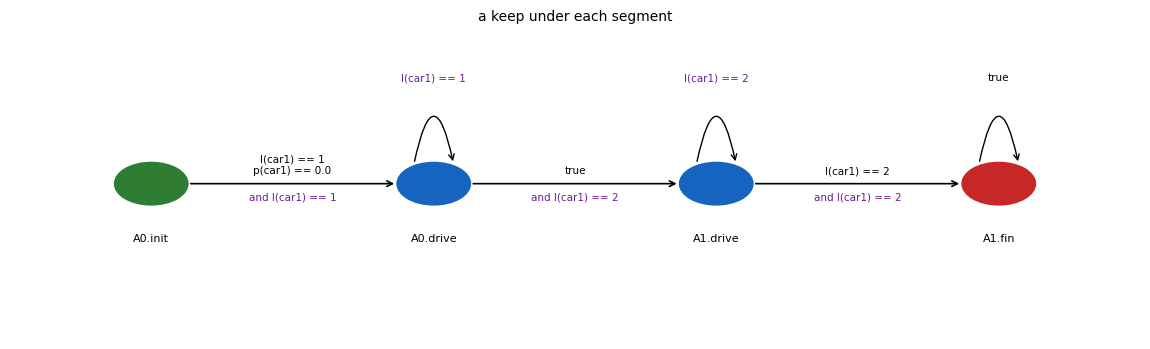

the two windows in the ASP program: keep 1 ends at T1 - 1, keep 2 starts at T1

goal(T1,T2,t) :-  goal1(T1),goal2(T2), 0 <= T1<=T2 <= t, keep_held(1,0,T1 - 1), keep_held(2,T1,T2).
:- query(t), not goal(_,_,t).
:- query(t), goal(_,_,t-1).
% keep 1: keep[A0.drive](l(car1) == 1), held from 0 to T1 - 1
keep_window(1,0,T1 - 1,t) :- goal(T1,_,t).
% keep 2: keep[A1.drive](l(car1) == 2), held from T1 to T2
keep_window(2,T1,T2,t) :- goal(T1,T2,t).

last step: 3
goal times, one tuple per valid split: [(3, 3)]
keep windows (keep, from, to): [(1, 0, 2), (2, 3, 3)]

car1
  t [s]          0    1    2    3
  position       0    1    9   15
  lane           1    1    1    2
  speed [mps]    1    8    6    9



In [7]:
e2 = run_experiment("e2_keep_two_lanes", spec("keep_lane_change_from_rest.osc"), RECOMMENDED)
fig = draw_automaton(spec("keep_lane_change_from_rest.osc"), "a keep under each segment")
plt.show()
print("the two windows in the ASP program: keep 1 ends at T1 - 1, keep 2 starts at T1\n")
show_lines(f"{e2}/instance.lp", ["% keep", "keep_held(1,0", "goal("])
print("\n" + open(f"{e2}/plan.txt").read())

the plan,the simulation

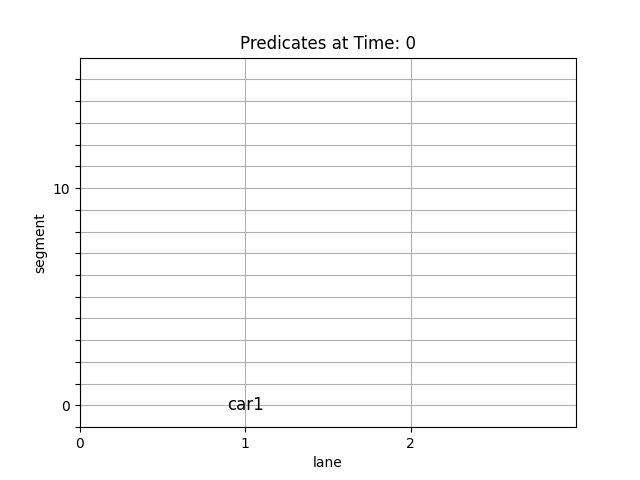
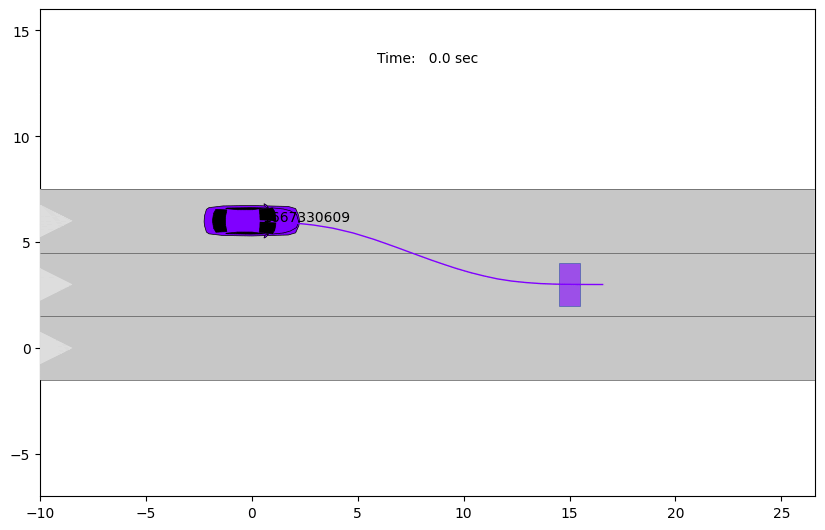

monitor verdict: POSITIVE
Watch the car: one lane change, after it has picked up speed, and no other.


In [8]:
show_images([("the plan", f"{e2}/plan.gif"), ("the simulation", f"{e2}/simulation.gif")])
print("monitor verdict:", open(f"{e2}/monitor.txt").readline().strip())
print("Watch the car: one lane change, after it has picked up speed, and no other.")

## 3. The standard's shorthands `keep_lane()` and `keep_speed()`

**What is new.** The domain model defines `keep_lane()` as `keep(actor.lane == lane)` against a
fresh parameter, which means "the lane never changes". Both forms now give the same invariant and
the same plans. No simulation needed, this is about the plans.

**Specs.** `tests/keep_lane_free.osc` (long form) and `tests/keep_lane_modifier.osc` (shorthand).

In [9]:
from planning.parse.TranslationGraphVisitor import TranslationGraphVisitor
show_code(TranslationGraphVisitor._build_stability_invariants)

rows, seen = [], {}
for name in ("keep_lane_free.osc", "keep_lane_modifier.osc"):
    plans, _, planner = plan_for(name, n=3)
    seen[name] = [(m.max_t, lanes_of(m, "car1"), lanes_of(m, "ego")) for m in plans]
    rows.append({"spec": name, "invariant": str(planner.translation_graph.invariants[0]),
                 "car1 lanes, first plan": seen[name][0][1]})
display(pd.DataFrame(rows).set_index("spec"))
print("identical first three plans:", seen["keep_lane_free.osc"] == seen["keep_lane_modifier.osc"])

planning/parse/TranslationGraphVisitor.py:568

  568      def _build_stability_invariants(self, modifier: str, arg_list: dict) -> set:
  569          if arg_list:
  570              raise ValueError(
  571                  f"{modifier}() takes no arguments, got {arg_list}. To fix a value, write for "
  572                  f"example lane(2) or keep(car1.lane == 2) instead."
  573              )
  574          # 'self' is replaced by the invoking actor in visitBehavior_invocation, which also sets
  575          # the scope to that invocation.
  576          return {StabilityInvariant("self", self.STABILITY_MODIFIERS[modifier])}
Initial setup saved to temporary file /tmp/nb_plan_5aal9irz/instance.lp!
Solving... t = 0
Solving... t = 1
Solving... t = 2


Solving... t = 3


Initial setup saved to temporary file /tmp/nb_plan_yd3giw5x/instance.lp!
Solving... t = 0
Solving... t = 1
Solving... t = 2


Solving... t = 3


,invariant,"car1 lanes, first plan"
spec,,
keep_lane_free.osc,"keep[scenario](car1.l == car1_lane, constant)","[2, 2, 2, 2]"
keep_lane_modifier.osc,"keep[c0.drive](car1.l == <free>, constant)","[2, 2, 2, 2]"


identical first three plans: True


## 4. Contradicting specifications have no plan

**What is new.** The standard describes inconsistent specifications (7.6.2.3) and gives no way to
detect them. Here an inconsistent specification is exactly an unsatisfiable ASP program. The
nonlocal case is the interesting one: no single step is impossible, only their interplay over time.

**Command.** `python tests/run_keep_tests.py` runs all of these among the keep tests.

In [10]:
rows = []
for name, note in [("keep_inconsistent_direct.osc", "two lane keeps on one car"),
                   ("keep_inconsistent_parallel.osc", "conflict across parallel branches"),
                   ("keep_inconsistent_nonlocal.osc", "only the interplay over time is impossible"),
                   ("duration_conflict_unsat.osc", "two phases of 3s or more inside 5s")]:
    try:
        plans, _, _ = plan_for(name)
        result = f"plan found at step {plans[0].max_t}"
    except NoModelException:
        result = "no plan, correctly"
    rows.append({"spec": name, "contradiction": note, "result": result})
display(pd.DataFrame(rows).set_index("spec"))

Initial setup saved to temporary file /tmp/nb_plan_u6sezc8o/instance.lp!
Solving... t = 0
Solving... t = 1
Solving... t = 2
Solving... t = 3
Solving... t = 4
Solving... t = 5
Solving... t = 6
Solving... t = 7
Solving... t = 8
Solving... t = 9
Solving... t = 10
Solving... t = 11
Initial setup saved to temporary file /tmp/nb_plan_6eg7uhr8/instance.lp!
Solving... t = 0


Solving... t = 1
Solving... t = 2


Solving... t = 3


Solving... t = 4


Solving... t = 5


...

Initial setup saved to temporary file /tmp/nb_plan_ilr6ol49/instance.lp!
Solving... t = 0
Solving... t = 1
Solving... t = 2
Solving... t = 3
Solving... t = 4
Solving... t = 5
Solving... t = 6
Solving... t = 7
Solving... t = 8
Solving... t = 9
Solving... t = 10
Solving... t = 11


Initial setup saved to temporary file /tmp/nb_plan_aij57q7m/instance.lp!
Solving... t = 0
Solving... t = 1
Solving... t = 2
Solving... t = 3


Solving... t = 4


Solving... t = 5


,contradiction,result
spec,,
keep_inconsistent_direct.osc,two lane keeps on one car,"no plan, correctly"
keep_inconsistent_parallel.osc,conflict across parallel branches,"no plan, correctly"
keep_inconsistent_nonlocal.osc,only the interplay over time is impossible,"no plan, correctly"
duration_conflict_unsat.osc,two phases of 3s or more inside 5s,"no plan, correctly"


## 5. Durations

**What is new.** `duration: [3s..20s]` on a composition or a single behavior used to be ignored. A
duration covering phases k1 to k2 now becomes `low <= T(k2) - T(k1-1) <= high` in the goal rule.

**Spec.** `tests/duration_invocation.osc`. **Command.** `python tests/run_duration_tests.py`.

In [11]:
from planning.Planner import Planner as _P
show_code(_P._duration_literals, 22)
plans, out, _ = plan_for("duration_invocation.osc", n=3)
print()
show_lines(f"{out}/instance.lp", ["% duration", "goal("])
for m in plans:
    print("plan: goal times", goal_witnesses(m), " so (T1-T0, T2-T1) =", [(a, b - a) for a, b in goal_witnesses(m)])

planning/Planner.py:203

  203      def _duration_literals(self, G, aut_path):
  204          """Goal-rule literals for the duration bounds, plus the top-level maximum if there is one.
  205  
  206          A duration covering phases k1..k2 bounds T(k2) - T(k1-1). Returns the literals as one
  207          string to append to the goal rule, the maximum of a duration that covers the whole plan,
  208          and comment lines for the instance.
  209          """
  210          literals, comments, cap = [], [], None
  211          last = f"T{len(aut_path) - 2}"
  212          for duration in sorted(G.durations, key=str):
  213              start, end = self._phase_window(duration.labels, aut_path, str(duration))
  214              span = end if start == "0" else f"{end} - {start}"
  215              if duration.low == duration.high:
  216                  literals.append(f"{span} = {duration.low}")
  217              else:
  218                  literals.append(f"{duration.low} <= {spa

Solving... t = 3


Solving... t = 4


Solving... t = 5



% duration[parallel](3..20s): from 0 to T2
% duration[the invocation A.drive](3..4s): from 0 to T1
% duration[the invocation B.drive](2..5s): from T1 to T2
goal(T1,T2,t) :-  goal1(T1),goal2(T2), 0 <= T1<=T2 <= t, 3 <= T2 <= 20, 3 <= T1 <= 4, 2 <= T2 - T1 <= 5.
:- query(t), not goal(_,_,t).
:- query(t), goal(_,_,t-1).
plan: goal times [(3, 5)]  so (T1-T0, T2-T1) = [(3, 2)]
plan: goal times [(3, 5)]  so (T1-T0, T2-T1) = [(3, 2)]
plan: goal times [(3, 5)]  so (T1-T0, T2-T1) = [(3, 2)]


## 6. The monitor checks keeps and the duration

**What is new.** The monitor used to check only that the goals were reached in order. A keep now
becomes a guard on the transitions entering its phase and on its self loop, mirroring the planner's
windows. Locations carry nothing, so this stays a plain symbolic automaton: a keep on a location is
compiled into the guards of every transition into it, self loop included. The scenario's duration becomes a guard on the current time. A step may also meet several
goals at once, as the planner allows.

**What this cell does.** Takes a plan, turns it into a trace, and breaks it on purpose. Only the
broken ones must be rejected.

**Command.** `python tests/run_monitor_tests.py`.

In [12]:
from monitoring import Monitor as M
show_code(M.guards_for_transition)
from run_monitor_tests import scale_time, set_at, stretch, valuations_from_plan, verdict

lane_plans, _, _ = plan_for("keep_adjacent_phases.osc")
lane_trace = stretch(valuations_from_plan(lane_plans[0]))
timed_plans, _, _ = plan_for("keep.osc")          # its scenario lasts [3s..20s]
timed_trace = stretch(valuations_from_plan(timed_plans[0]))

rows = []
for which, label, trace, expected in [
        ("keep_adjacent_phases.osc", "the plan's own trace", lane_trace, True),
        ("keep_adjacent_phases.osc", "lane wrong at the first step", set_at("l(car1)", 0, 2)(lane_trace), False),
        ("keep.osc", "the plan's own trace", timed_trace, True),
        ("keep.osc", "same trace, 20 times too fast", scale_time(0.05)(timed_trace), False),
        ("keep.osc", "same trace, 10 times too slow", scale_time(10)(timed_trace), False)]:
    accepted = verdict(spec(which), trace)
    rows.append({"spec": which, "trace": label, "verdict": "accepted" if accepted else "rejected",
                 "as intended": accepted == expected})
display(pd.DataFrame(rows).set_index(["spec", "trace"]))

monitoring/Monitor.py:235

  235  def guards_for_transition(source, target, final, guards):
  236      """The keep guards that apply to one transition, as a list of nodes.
  237  
  238      A keep is checked on the step that enters its location and on every step that stays there, so
  239      it goes on the incoming transitions and the self loop, never on the one that leaves. The edge
  240      into the final location is the exception: nothing follows it, so the last segment's keep has
  241      to cover that step. This mirrors the ASP windows, which tile the plan as [T(k-1), Tk) with
  242      only the last phase closed. See section 6 of docs/keep-spec.md.
  243      """
  244      applicable = []
  245      for covered, node in guards:
  246          if target in covered or (target == final and source in covered):
  247              applicable.append(node)
  248      return applicable
Initial setup saved to temporary file /tmp/nb_plan_oay1l225/instance.lp!
Solving... t = 0
Solvi

Solving... t = 3


Solving... t = 4


Solving... t = 5


Solving... t = 6


Solving... t = 7


Solving... t = 8


Solving... t = 9


verdict  as intended
spec                     trace                                               
keep_adjacent_phases.osc the plan's own trace           accepted         True
                         lane wrong at the first step   rejected         True
keep.osc                 the plan's own trace           accepted         True
                         same trace, 20 times too fast  rejected         True
                         same trace, 10 times too slow  rejected         True

## 7. Experiment: can the simulation hold a requested speed

**Finding.** Frenetix's velocity planner reads only the first goal state of a planning problem. Our
plans have one goal state per waypoint, so after the first one Frenetix had no speed target and
overshot. The patch aims at the current waypoint and clamps to its speed window.

**Spec.** `tests/speed_rampup_then_hold.osc`: reach 6mps, then hold it.

**Settings.** `ROADLOGIC_VELOCITY_PATCH=0` or `1`. The patch changes nothing inside Frenetix, it is a
wrapper in `commonroad_extensions/scenario_execution/velocity_patch.py`.

In [13]:
from commonroad_extensions.scenario_execution import velocity_patch
show_code(velocity_patch.calculate_desired_velocity, 35)

commonroad_extensions/scenario_execution/velocity_patch.py:65

   65  def calculate_desired_velocity(self, x_0, s_position) -> float:
   66      """Aim for the current waypoint, inside the speed window the plan asked for."""
   67      goal_state = current_goal_state(self.planning_problem, x_0.time_step)
   68      if goal_state is None:
   69          return getattr(self, _ATTRIBUTE)(x_0, s_position)
   70  
   71      bounds = velocity_bounds(goal_state)
   72  
   73      target = None
   74      position = getattr(goal_state, "position", None)
   75      center = getattr(position, "center", None) if position is not None else None
   76      interval = getattr(goal_state, "time_step", None)
   77      if center is not None and interval is not None:
   78          goal_s = self._calculate_goal_s_position([center])
   79          # aim at the middle of the arrival window, as the original does
   80          remaining_steps = (interval.start + interval.end) / 2 - x_0.time_step
   81   

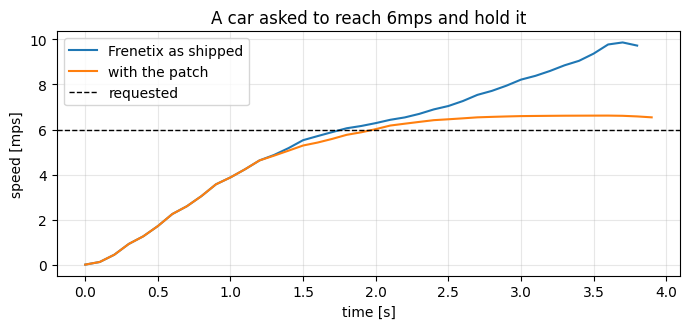

Frenetix as shipped,with the patch

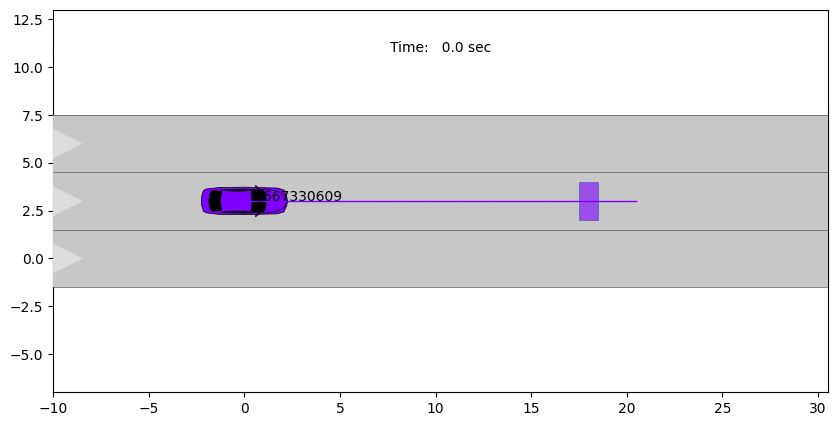
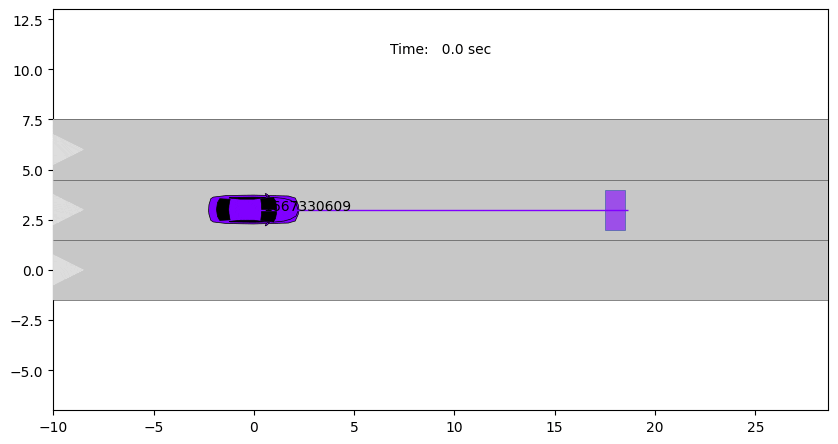

In [14]:
stock = run_experiment("e7_speed_without_patch", spec("speed_rampup_then_hold.osc"), RECOMMENDED)
patched = run_experiment("e7_speed_with_patch", spec("speed_rampup_then_hold.osc"), PATCHED)

fig, ax = plt.subplots(figsize=(7, 3.4))
for label, name in (("Frenetix as shipped", "e7_speed_without_patch"), ("with the patch", "e7_speed_with_patch")):
    frame = pd.read_csv(os.path.join(simulation_folder(name), "CURRV.csv")).sort_values("time")
    ax.plot(frame["time"], frame["velocity"], label=label)
ax.axhline(6, color="black", linestyle="--", linewidth=1, label="requested")
ax.set_xlabel("time [s]"); ax.set_ylabel("speed [mps]"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("A car asked to reach 6mps and hold it")
fig.tight_layout(); fig.savefig(os.path.join(OUT, "e7_speed_curves.png"), dpi=150); plt.show()

show_images([("Frenetix as shipped", f"{stock}/simulation.gif"), ("with the patch", f"{patched}/simulation.gif")])

## 8. Known problem, and a fix: the patch caused a collision with two cars

**Finding.** With the patch on as committed, the two-car overtake from section 1 crashes after 2.1s,
and so does the paper's own benchmark, after 3.5s. car1 crawls
at 1.7 m/s and ego, accelerating normally, rear-ends it before its lane change.

**Cause.** A bug in how the plan's speed reached Frenetix. In `dynamics.lp` a car's position at t is
its position at t-1 plus its speed at t-1, so the speed the plan stores at a waypoint is the speed the
car *leaves* it with. car1 reaches its t=4 waypoint at 8 m/s and then slows to 1, so it was given the
window 0 to 2 m/s, and the patch held it there from the start.

**Three fixes tried,** each behind a switch, defaults untouched:

| switch | idea |
|---|---|
| `ROADLOGIC_VELOCITY_PATCH_MODE=average` | drop the clamp, only aim to reach each waypoint on time |
| `ROADLOGIC_GOAL_VELOCITY_SOURCE=segment` | window from the plan's average speed over the stretch to the waypoint |
| `+ ROADLOGIC_GOAL_VELOCITY_SCOPE=constrained` | and only for cars whose speed the spec constrains |

Every simulated car starts from rest and the plans do not, so cars run behind the plan's schedule.
Keeping time then means driving faster than planned, which is right for an overtake and wrong for a
car asked to hold a speed. The third fix settles it by asking the specification which one it wants.
The table reads the runs from `demo_output/`, each with its `commands.sh`.

In [15]:
cases = {
    "two-car overtake": ("tests/keep_scenario_scope.osc", {
        "no patch": "e1_keep_one_lane", "patch as committed": "e8_overtake_with_patch",
        "average": "f1_overtake_average", "segment": "f2_overtake_segment",
        "segment, constrained only": "f3_overtake"}),
    "benchmark exp_002": ("experiments_src/exp_002/in/spec.osc", {
        "no patch": "e9_benchmark", "patch as committed": "e8_benchmark_with_patch",
        "average": "f1_benchmark_average",
        "segment": "f2_benchmark_segment", "segment, constrained only": "f3_benchmark"}),
}
rows = defaultdict(dict)
for case, (case_spec, runs) in cases.items():
    for label, name in runs.items():
        if case == "two-car overtake":
            f = simulation_folder(name)
            rows[label][case] = f"{monitor_verdict(case_spec, f)}, {simulation_length(f):.1f}s"
        else:
            rows[label][case] = " / ".join(monitor_verdict(case_spec, simulation_folder(name, s))
                                           for s in ("scenario_0001", "scenario_0002"))
for label, name in {"no patch": "e7_speed_without_patch", "patch as committed": "e7_speed_with_patch",
                    "average": "f1_ramp_average", "segment": "f2_ramp_segment",
                    "segment, constrained only": "f3_ramp"}.items():
    v = pd.read_csv(os.path.join(simulation_folder(name), "CURRV.csv"))
    rows[label]["single car, hold 6 m/s"] = (f"peak {v.velocity.max():.2f}, "
                                             f"mean after 2s {v[v.time >= 2].velocity.mean():.2f}")
order = ["no patch", "patch as committed", "average", "segment", "segment, constrained only"]
display(pd.DataFrame(rows).T.loc[order, ["two-car overtake", "single car, hold 6 m/s", "benchmark exp_002"]].fillna("not run"))

,two-car overtake,"single car, hold 6 m/s",benchmark exp_002
no patch,"POSITIVE, 9.5s","peak 9.87, mean after 2s 8.01",POSITIVE / POSITIVE
patch as committed,"negative, 2.1s","peak 6.62, mean after 2s 6.49",negative / negative
average,"POSITIVE, 9.5s","peak 9.87, mean after 2s 8.01",POSITIVE / POSITIVE
segment,"POSITIVE, 9.6s","peak 6.62, mean after 2s 6.49",negative / negative
"segment, constrained only","POSITIVE, 9.3s","peak 6.62, mean after 2s 6.49",POSITIVE / POSITIVE


patch as committed: collision,with the fix

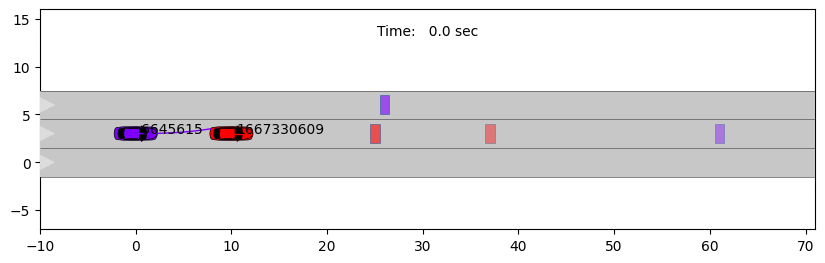
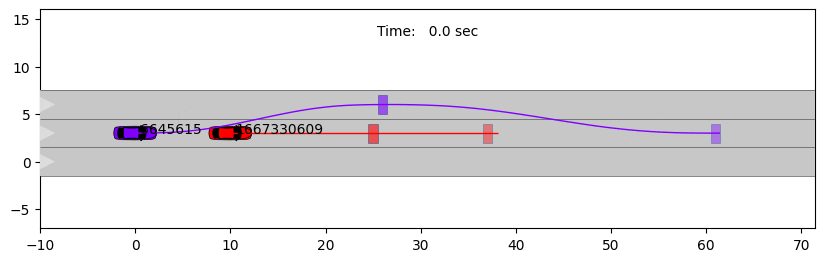

In [16]:
show_images([("patch as committed: collision", f"{OUT}/e8_overtake_with_patch/simulation.gif"),
             ("with the fix", f"{OUT}/f3_overtake/simulation.gif")])

**A side note from testing the fix.** `tests/speed_overtake_keep.osc` (car1 holds 5 m/s while ego
overtakes) collides in simulation with *any* settings, paper settings included, at about 7.5s. Its last
goal merges ego back only 5 to 10 m ahead of car1, which the motion planner cannot do safely. That is a
problem with the specification, the same one `keep.osc` had before its gap was widened to 13 to 25 m.
With the fix, car1's speed stays between 4.99 and 5.65 m/s there, against 4.99 to 7.16 without.

**Since then.** For a car whose speed the spec constrains, a window spanning the *range* of speeds
the plan uses on a stretch (`ROADLOGIC_GOAL_VELOCITY_SOURCE=range`) works better than the average,
which pinned an accelerating car to half its target speed (section 11). Cars without a speed
constraint get no window under the fix, so the overtake and benchmark rows hold unchanged.

## 9. Experiment: which verdict algebra

**Finding.** MinMax returns a number that mixes lanes and metres, one lane apart counting as one
metre apart. Plain boolean is meaningless on simulated floats, a position a fraction of a millimetre
off fails the whole trace. The new default is boolean with a 1e-3 tolerance on continuous values,
the same slack the summary script always applied to the MinMax cost. It has to agree with MinMax
on the benchmark, or every number in the paper moves.

**Spec.** `experiments_src/exp_002/in/spec.osc`, the paper's overtake, run with paper settings.

In [17]:
import math
from monitoring.Monitor import TolerantBooleanMonitor
from syma_arv.monitor.boolean import BooleanMonitor
from syma_arv.monitor.minmax import MinMaxMonitor
from monitoring.Monitor import Monitor

bench_spec = os.path.join("experiments_src", "exp_002", "in", "spec.osc")
run_experiment("e9_benchmark", bench_spec, PAPER, scenarios=2)

def final(spec_path, folder, ring):
    mon = Monitor.from_osc2_file(spec_path, ring=ring)
    mon.eval_trace(folder, log_name_override="nb_ring")
    return mon.state[[l for l in mon.syma_aut.locations if l.final][0]]

rows = []
for scenario in ("scenario_0001", "scenario_0002"):
    folder = simulation_folder("e9_benchmark", scenario)
    cost = float(final(bench_spec, folder, MinMaxMonitor))
    rows.append({"scenario": scenario, "minmax cost": cost,
                 "minmax verdict": "positive" if math.isclose(cost, 0, abs_tol=1e-3) else "negative",
                 "tolerant boolean": "positive" if not final(bench_spec, folder, TolerantBooleanMonitor) else "negative",
                 "strict boolean": "positive" if not final(bench_spec, folder, BooleanMonitor) else "negative"})
display(pd.DataFrame(rows).set_index("scenario"))

,minmax cost,minmax verdict,tolerant boolean,strict boolean
scenario,,,,
scenario_0001,0.0001,positive,positive,negative
scenario_0002,0.0001,positive,positive,negative


## 10. A speed keep needs a tolerance, and clocks

**What is new.** The planner's world is discrete, one unit is one metre or one mps. A simulated trace
is sampled every 0.1s and crosses 6.000 without landing on it, so `speed(6mps)` could never hold. A
required equality on a position or a speed now holds within half a unit: `EQUALITY_TOLERANCE = 0.5` in
`monitoring/Monitor.py`, overridable with `ROADLOGIC_EQUALITY_TOLERANCE`. Lanes stay exact. The value
may need tuning.

**The check.** Every simulated run in this notebook, with the tolerance off and on. Nothing about the
keeps or the benchmark changes. Only the speed hold does, and there the unpatched run, which reached
almost 10 m/s, passes too. Its keep window can shrink to the one moment the speed was near 6. A
duration on that segment prevents it, and section 11 checks one with a clock.

In [18]:
import monitoring.Monitor as MM

speeds = pd.read_csv(os.path.join(simulation_folder("e7_speed_with_patch"), "CURRV.csv"))["velocity"]
print(f"closest sample to 6.000: {abs(speeds - 6).min():.4f} mps off, "
      f"{(abs(speeds - 6) <= 1e-3).sum()} samples within 1e-3, {(abs(speeds - 6) <= 0.5).sum()} within 0.5\n")

# the same speed spec without the duration on its second segment, which the monitor cannot check yet
variant = os.path.join(OUT, "speed_hold_without_segment_duration.osc")
with open(variant, "w") as f:
    f.write(open(spec("speed_rampup_then_hold.osc")).read().replace("car1.drive(duration: [3s..6s])", "car1.drive()"))

runs = [("keep one lane", spec("keep_scenario_scope.osc"), "e1_keep_one_lane", "scenario_0001"),
        ("keep one lane, with the fix", spec("keep_scenario_scope.osc"), "f3_overtake", "scenario_0001"),
        ("keep two lanes", spec("keep_lane_change_from_rest.osc"), "e2_keep_two_lanes", "scenario_0001"),
        ("benchmark 1", bench_spec, "e9_benchmark", "scenario_0001"),
        ("benchmark 2", bench_spec, "e9_benchmark", "scenario_0002"),
        ("hold 6 m/s, patched (holds 6.5)", variant, "e7_speed_with_patch", "scenario_0001"),
        ("hold 6 m/s, unpatched (peaks 9.87)", variant, "e7_speed_without_patch", "scenario_0001")]
rows = []
for label, s, name, scenario in runs:
    row = {"run": label}
    for tol in (0.0, 0.5):
        MM.EQUALITY_TOLERANCE = tol
        MM.Monitor.from_osc2_file.__func__.cache_clear()
        row[f"tolerance {tol}"] = monitor_verdict(s, simulation_folder(name, scenario))
    rows.append(row)
MM.EQUALITY_TOLERANCE = 0.5
MM.Monitor.from_osc2_file.__func__.cache_clear()
display(pd.DataFrame(rows).set_index("run"))
print("the original spec, with its duration on the second segment:",
      monitor_verdict(spec("speed_rampup_then_hold.osc"), simulation_folder("e7_speed_with_patch")))

closest sample to 6.000: 0.0164 mps off, 0 samples within 1e-3, 10 within 0.5



,tolerance 0.0,tolerance 0.5
run,,
keep one lane,POSITIVE,POSITIVE
"keep one lane, with the fix",POSITIVE,POSITIVE
keep two lanes,POSITIVE,POSITIVE
benchmark 1,POSITIVE,POSITIVE
benchmark 2,POSITIVE,POSITIVE
"hold 6 m/s, patched (holds 6.5)",negative,POSITIVE
"hold 6 m/s, unpatched (peaks 9.87)",negative,POSITIVE


the original spec, with its duration on the second segment: negative


## 11. Clocks: a duration on any segment

**What is new.** A duration on a segment that starts partway through, like the 3 to 6 s hold below,
needs the time that segment began. The monitor follows many runs at once, one per way of splitting the
trace into segments, and they began it at different times. So the monitor now keeps, per run, the
time each open duration region was entered. Entering a region starts its clock, and leaving it checks
`low <= now - start <= high`. A duration on the top-level composition keeps its simple guard on the
current time from section 6, which stays inside plain symbolic automata. The clocks do not: they are
per-run state, which makes this a timed automaton. `ROADLOGIC_TIMED_MONITOR=0` switches them off.

**Spec.** `tests/speed_rampup_then_hold_timed.osc`: reach 6 m/s within 2 to 4 s, then hold it for 3 to
6 s. The duration on the ramp makes the plan spend time accelerating, as a real car must. Without it
the plan starts the car at 6 m/s, its start speed being free, and the hold in simulation comes out far
shorter than the plan promised.

**Command.** `python tests/run_monitor_tests.py duration_invocation.osc` runs the clock tests.

In [19]:
import monitoring.Monitor as MM
show_code(MM.TimedBooleanMonitor._clocks_after)

monitoring/Monitor.py:282

  282      def _clocks_after(self, starts, crossed, target, now):
  283          """The open regions after a step, or None when the step breaks a duration."""
  284          starts = dict(starts)
  285          for index, (covered, duration) in enumerate(self.regions):
  286              if index in starts:
  287                  if target not in covered:
  288                      if not duration.low <= now - starts.pop(index) <= duration.high:
  289                          return None
  290              elif target in covered:
  291                  starts[index] = now
  292              elif any(node in covered for node in crossed[1:]):
  293                  # a shortcut ran through the whole region in one step, so it lasted no time
  294                  if not duration.low <= 0 <= duration.high:
  295                      return None
  296          return tuple(sorted(starts.items()))


**What the clocks found.** Three simulations of the timed spec, plus the old run that peaked at
9.87 m/s. With the range windows the car holds 6 ± 0.5 from 2.9 s to the end of the run at 5.7 s, so
2.8 s. The spec asks for 3 s and the run is rejected, correctly. The planner lets a car change speed by
8 m/s in one second (`max_velocity_change_lon` in `constants.lp`), so the plan reaches 6 m/s in one
step, while the simulated car needs 2.9 s. Against a variant asking for a 2 s hold, the range fix passes
and every other run fails, the 9.87 run included. Before the clocks, that one passed.

,speed after 3s,hold 3s to 6s (the spec),hold 2s to 6s
run,,,
range windows (the fix),5.60 to 6.05,negative,POSITIVE
no patch,6.16 to 6.52,negative,negative
segment windows,3.18 to 6.03,negative,negative
"old spec's run, peaked at 9.87",8.22 to 9.87,negative,negative


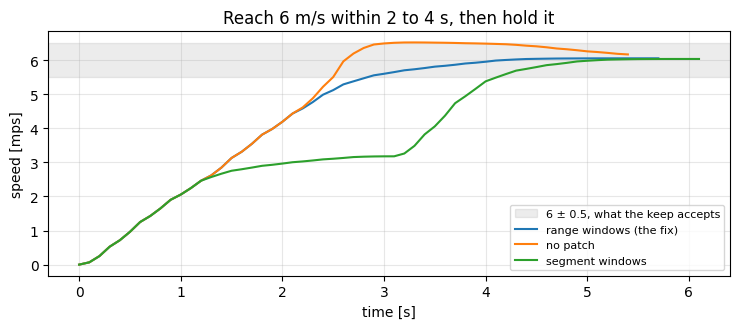

In [20]:
timed = spec("speed_rampup_then_hold_timed.osc")
two_seconds = os.path.join(OUT, "speed_hold_2s.osc")
with open(two_seconds, "w") as f:
    f.write(open(timed).read().replace("A1: car1.drive(duration: [3s..6s])", "A1: car1.drive(duration: [2s..6s])"))

runs = [("range windows (the fix)", "g2_timed_ramp_with_range_fix"),
        ("no patch", "g1_timed_ramp_without_patch"),
        ("segment windows", "g1_timed_ramp_with_fix"),
        ("old spec's run, peaked at 9.87", "e7_speed_without_patch")]
rows = []
for label, name in runs:
    v = pd.read_csv(os.path.join(simulation_folder(name), "CURRV.csv"))
    late = v[v.time >= 3].velocity
    rows.append({"run": label, "speed after 3s": f"{late.min():.2f} to {late.max():.2f}",
                 "hold 3s to 6s (the spec)": monitor_verdict(timed, simulation_folder(name)),
                 "hold 2s to 6s": monitor_verdict(two_seconds, simulation_folder(name))})
display(pd.DataFrame(rows).set_index("run"))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.axhspan(5.5, 6.5, color="grey", alpha=0.15, label="6 ± 0.5, what the keep accepts")
for label, name in runs[:3]:
    v = pd.read_csv(os.path.join(simulation_folder(name), "CURRV.csv")).sort_values("time")
    ax.plot(v.time, v.velocity, label=label)
ax.set_xlabel("time [s]"); ax.set_ylabel("speed [mps]"); ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="lower right")
ax.set_title("Reach 6 m/s within 2 to 4 s, then hold it")
fig.tight_layout(); fig.savefig(os.path.join(OUT, "g_timed_ramp_speeds.png"), dpi=150); plt.show()

## Where to continue

1. **Choose the default for the speed patch.** Recommended is the fix: speed windows from the range of
   planned speeds, only for cars whose speed the spec constrains
   (`ROADLOGIC_GOAL_VELOCITY_SOURCE=range`, `ROADLOGIC_GOAL_VELOCITY_SCOPE=constrained`). The other choice
   is the patch off. As committed, the paper's benchmark collides. The paper's settings stay one switch
   away either way: `ROADLOGIC_VELOCITY_PATCH=0 ROADLOGIC_GOAL_VELOCITY=0`.
2. **Calibrate the planner's acceleration** to the simulator. `max_velocity_change_lon = 8` lets a plan go
   from rest to 6 m/s in one second where a simulated car needs about three (section 11). This changes
   every plan, so it is a decision with consequences for the paper.
3. **Tune `EQUALITY_TOLERANCE`.** At 0.5 it rejects stock Frenetix for peaking at 6.52 (section 11).
4. **Widen the merge-back gap in `tests/speed_overtake_keep.osc`**, which collides with any settings.
5. **Speed experiments for the paper**, built from sections 7, 8, 10 and 11.
6. Smaller: soft `default` keeps and `remove_default` are still unsupported.

Every run in this notebook can be repeated from its `demo_output/<experiment>/commands.sh`.